# D38. 음성 번역 & 다국어 에이전트: 외국인 환자의 전화를 통역하기

**음성 AI 전문가 과정 | 8주차 M8 차세대 음성 모델 · 다국어 · 데이터 · TTS 파인튜닝 | 4시간**

## 학습 목표
1. Whisper로 **말한 언어를 감지**하고, 받아쓰기(`transcribe`)와 영어 번역(`translate`)의 차이, 한 문장에 두 언어가 섞일 때(코드 스위칭)의 동작을 확인한다.
2. 음성 번역의 세 가지 길 — **Cascade(받아쓰기 → 번역)**, **직접 음성 번역(SeamlessM4T)**, **Whisper translate** — 을 같은 문장으로 비교하고, **BLEU · chrF · 용어 정확도**로 품질을 잰다.
3. **문장 단위 통역**과 **부분 출력 통역**의 지연을 비교하고, 앞부분이 뒤집히지 않게 확정하는 방법(이전 번역과의 공통 앞부분)을 구현한다.
4. D31의 WebSocket 서버 위에 **한 ↔ 영 통역 엔드포인트**(`/ws/interpret`)를 만들고, 언어 감지 → 받아쓰기 → 번역 → 역번역 확인 → 합성의 지연을 재며, 의료 통역의 한계를 말할 수 있다.

## 오늘의 실습 흐름
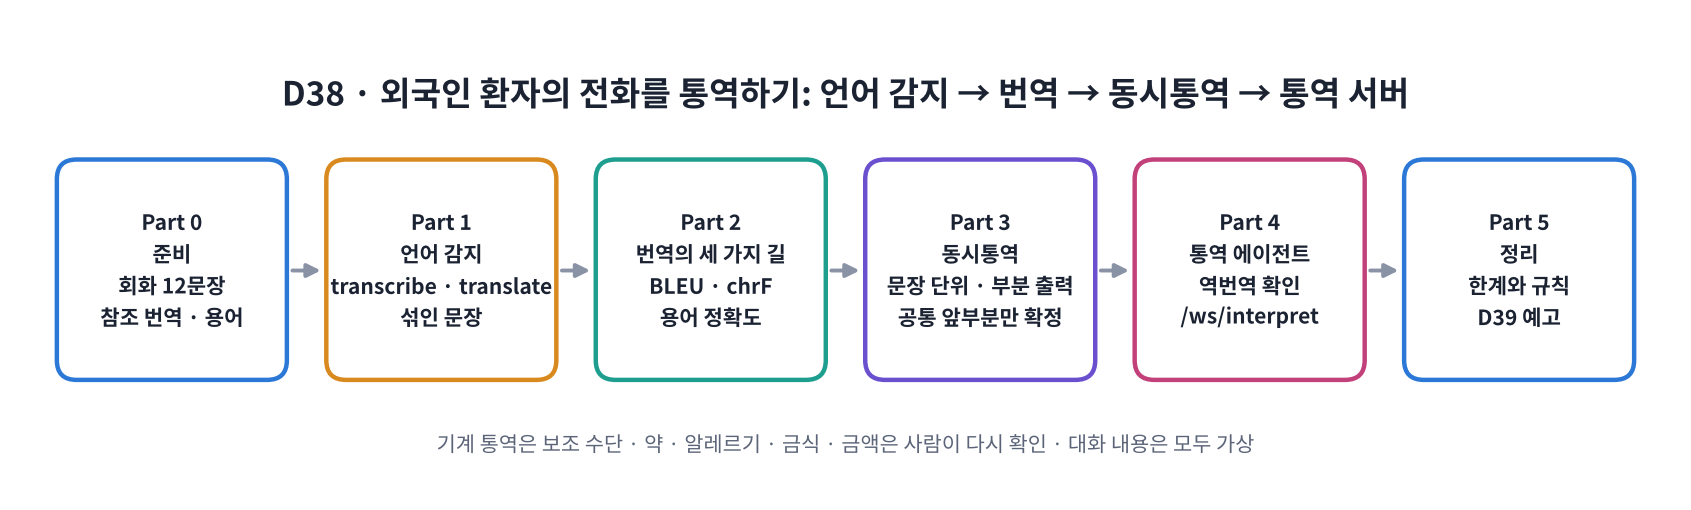

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | 언어 감지, Whisper transcribe vs translate, 한 문장 안 언어 섞기 | Part 0 ~ 1 · ✍️ 직접 작성 1 (한글 비율) | 언어 감지 표 · 섞인 문장 표 |
| 2교시 | 번역의 세 가지 길, BLEU · chrF · 용어 정확도 | Part 2 · ✍️ 직접 작성 2 (짧은 번역 벌점) | **번역 품질 비교표** |
| 3교시 | 동시통역: 문장 단위 vs 부분 출력, 확정 규칙 | Part 3 · ✍️ 직접 작성 3 (공통 앞부분) | 통역 타임라인 · 지연 표 |
| 4교시 | 목소리 일관성, 통역 파이프라인, WebSocket 엔드포인트, 한계 | Part 4 ~ 5 · ✍️ 직접 작성 4 (통역 방향) · 워크시트 25문항 | **한 ↔ 영 통역 WebSocket** · 지연 표 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day38/animation.html) | 언어 감지(D38-2) · 번역의 세 가지 길(D38-3) · BLEU(D38-4) · 어순과 통역(D38-5) · 문장 단위 vs 부분 출력(D38-6) · 역번역 확인(D38-7) · 통역 지연(D38-8). 탭마다 **▶ 시연 보기**를 누르면 자막과 함께 스스로 움직입니다 |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day38/worksheet.html) | 수업을 모두 마친 뒤 하루 한 장 25문항 (객관식 · OX · 모두 고르기 · 선 잇기 · 순서 · 코드 직접 쓰기 · 계산 · 분류 · 직접 조작), 오답 정리 → 노션 |

## 이 노트북 사용법
- ▶️ 위에서부터 차례로 실행합니다. **키가 필요 없습니다.** 번역 모델(SeamlessM4T v2, 약 9 GB)을 내려받는 데 3 ~ 5분 걸립니다.
- ⭐ **핵심 코드** 셀은 완성된 코드입니다. 실행한 뒤 `# ⭐` 표시가 붙은 줄을 읽어 보세요. 🔍 **핵심 줄 해설 보기**를 누르면 설명이 펼쳐집니다.
- ✍️ **직접 작성** 셀은 교시마다 하나씩, 모두 네 개입니다. `...` 자리에 코드를 직접 쓰고 실행하면 ✅ 또는 ❌가 나옵니다. 막히면 💡 **힌트 보기**, 다 쓴 뒤에는 🔑 **정답 보기**를 누르세요. 작성하지 않아도 아래 셀은 그대로 실행됩니다.
- ✏️ 표시 줄은 값을 **직접 바꿔** 다시 실행해 보는 줄입니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 규칙 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 토론 |
| 🎧 **들어 보기** | 소리로 확인 |

> ⚙️ **런타임 → T4 GPU** 필요(번역 모델). 오늘 쓰는 목소리는 모두 **합성 음성**이고, 환자 · 병원 · 대화 내용은 가상입니다.
>
> ⚖️ **오늘의 약속**: 기계 통역은 **틀립니다.** 약 이름 · 알레르기 · 금식 같은 안내가 틀리면 사람이 다칩니다. 오늘 만드는 통역기에는 **"확인 필요" 표시**를 넣고, 중요한 내용은 사람이 다시 확인하는 것을 전제로 합니다(Part 4).

> 🎬 **애니메이션 D38-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day38/animation.html#flow) — 환자의 영어와 직원의 한국어가 통역기를 사이에 두고 오가는 과정

## Part 0. 준비

> 🛠️ 번역 품질을 재는 `sacrebleu`와 D31에서 쓴 서버 도구(`fastapi` · `uvicorn` · `websockets`)를 설치합니다. Whisper · Edge TTS는 D27 ~ D37과 같습니다.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt soundfile uroman edge-tts sacrebleu
!pip install -q -c colab_constraints.txt fastapi uvicorn websockets     # 4교시 통역 서버 (D31과 같음)
print("✅ 설치 완료")

In [ ]:
import os, re, io, sys, json, time, math, random, asyncio, threading, warnings, logging, tempfile, functools
import numpy as np
import pandas as pd
import librosa
import torch
import requests
import soundfile as sf
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display, Markdown
import sacrebleu                                         # 번역 품질 지표 BLEU · chrF
import uvicorn, websockets                               # 서버 실행기 · WebSocket 클라이언트 (D31)
from fastapi import FastAPI, WebSocket, WebSocketDisconnect
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000                                               # 말소리 분석용 (Whisper · 감정 · AST)
print(" · ".join(f"{p} {md.version(p)}" for p in ["transformers", "sacrebleu", "fastapi", "torch"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 가능, 조금 느림)")

def verify(cond, what=""):                               # ⭐ 핵심 코드 셀: 결과가 예상과 같은지 스스로 확인
    print(f"✅ 확인: {what}" if cond else f"⚠️ 예상과 다릅니다: {what} → 위 셀을 고쳤다면 원래대로 되돌려 다시 실행하세요.")

def practice(run, want, tol=1e-4):                       # ✍️ 직접 작성 셀 채점: 아직 안 썼거나 오류가 나도 노트북은 계속 실행됨
    try:
        got = run()
    except Exception as e:
        print(f"❌ 실행 중 오류가 났습니다 ({type(e).__name__}: {str(e)[:90]}) · 아래 💡 힌트 보기를 눌러 보세요."); return False
    items = got if isinstance(got, (list, tuple)) else [got]
    if any(x is None or x is Ellipsis for x in items):
        print("✍️ 아직 작성 전입니다. '...' 줄을 지우고 코드를 쓴 뒤 다시 실행하세요. (작성하지 않아도 아래 셀은 그대로 실행됩니다)"); return False
    try:
        ok = bool(np.allclose(np.asarray(got, float), np.asarray(want, float), atol=tol))
    except (TypeError, ValueError):
        ok = list(items) == list(want if isinstance(want, (list, tuple)) else [want])
    show = lambda v: str([round(float(x), 4) if isinstance(x, (int, float, np.floating)) else x for x in (v if isinstance(v, (list, tuple)) else [v])])[:110]
    print("✅ 정답입니다! 🎉" if ok else f"❌ 결과가 다릅니다. 내 결과 {show(got)} · 기대 {show(want)} · 아래 💡 힌트 보기를 눌러 보세요.")
    return ok

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    if len(y): display(Audio(y, rate=sr))
    else: print("   (소리 없음: 위의 경고 · 오류를 확인하세요)")

def silence(sec, sr=SR):
    return np.zeros(int(sec * sr), np.float32)

In [ ]:
# 🔊 모델 준비 (D27 ~ D37과 같음): 받아쓰기 Whisper · 합성 Edge TTS (예비 MMS-TTS)
from transformers import AutoTokenizer, VitsModel, WhisperProcessor, WhisperForConditionalGeneration
import uroman as ur
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

import functools, tempfile
VOICE_BOT, VOICE_USER = "ko-KR-SunHiNeural", "ko-KR-InJoonNeural"   # ✏️ Edge 신경망 음성: 비서 · 사용자 대역
TTS_ENGINE = "edge"                                      # 인터넷 · 서비스 문제로 실패하면 자동으로 "mms"(예비)

@functools.lru_cache(maxsize=512)                        # 같은 문장은 다시 요청하지 않음
def _edge_tts(text, voice):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice).save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)   # MP3 24 kHz → 16 kHz
    finally:
        os.remove(path)

def _mms_tts(text, seed=0):                              # 예비: MMS-TTS 한국어 VITS (D16)
    set_seed(seed)
    enc = tts_tok(U.romanize_string(text), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return to_np(tts_model(**enc).waveform[0])

def tts(text, seed=0, voice=None):                       # 글자 → 16 kHz 소리: Edge 신경망 음성, 실패하면 MMS-TTS
    global TTS_ENGINE
    if TTS_ENGINE == "edge":
        try:
            return _edge_tts(text, voice or VOICE_BOT).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    return _mms_tts(text, seed)

def user_tts(text, seed=0):                              # 사용자 대역 목소리: 비서와 다른 목소리 (MMS 예비일 때는 3반음 낮춰 구분)
    y = tts(text, seed=seed, voice=VOICE_USER)
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=-3) if TTS_ENGINE == "mms" else y

def stt(y):                                              # 16 kHz 소리 → 글자
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def make_voice(text):                                    # 앞 0.5초 · 뒤 1초 조용함을 붙인 '사용자 말'
    y = np.concatenate([silence(0.5), user_tts(text), silence(1.0)]).astype(np.float32)
    return y / (np.abs(y).max() + 1e-9) * 0.8

print("받아쓰기 확인:", stt(tts("한빛치과입니다. 무엇을 도와드릴까요?")))

In [ ]:
# 📒 오늘의 재료: 한빛치과 회화 12문장 (환자 영어 6 · 직원 한국어 6) + 사람이 쓴 참조 번역 + 꼭 맞아야 하는 용어
VOICES = {"ko": "ko-KR-SunHiNeural", "en": "en-US-AvaNeural"}     # ✏️ 통역 결과를 읽어 줄 목소리 (언어마다 하나)
PATIENT, STAFF = "en-US-AndrewNeural", "ko-KR-InJoonNeural"      # 환자(영어) · 직원(한국어) 대역 목소리
LANG_KO = {"ko": "한국어", "en": "영어", "ja": "일본어", "zh": "중국어"}

def speak(text, lang=None, voice=None):                  # 글자 → 16 kHz 소리 (언어에 맞는 목소리로)
    return tts(text, voice=voice or VOICES[lang])

PAIRS = [  # src: 말한 언어 · text: 한 말 · ref: 참조 번역 · terms: 번역에 꼭 있어야 할 낱말 묶음 (묶음마다 하나라도 있으면 통과)
    dict(src="en", text="Hello, I have a terrible toothache. Can I see a dentist today?", ref="안녕하세요, 이가 너무 아파요. 오늘 진료받을 수 있을까요?", terms=[["이가", "치통", "이빨"], ["오늘"]]),
    dict(src="en", text="I would like to book a teeth cleaning for next Wednesday.", ref="다음 주 수요일에 스케일링을 예약하고 싶어요.", terms=[["스케일링", "치석", "클리닝"], ["수요일"]]),
    dict(src="en", text="My wisdom tooth hurts when I chew.", ref="씹을 때 사랑니가 아파요.", terms=[["사랑니"]]),
    dict(src="en", text="I am allergic to penicillin.", ref="저는 페니실린 알레르기가 있어요.", terms=[["페니실린"], ["알레르기", "알러지"]]),
    dict(src="en", text="How much does a root canal cost?", ref="신경 치료 비용은 얼마인가요?", terms=[["신경 치료", "신경치료", "근관"]]),
    dict(src="en", text="Do you accept travel insurance?", ref="여행자 보험이 적용되나요?", terms=[["보험"]]),
    dict(src="ko", text="성함과 생년월일을 말씀해 주세요.", ref="Please tell me your name and date of birth.", terms=[["name"], ["birth"]]),
    dict(src="ko", text="오늘 오후 세 시에 진료 가능합니다.", ref="We can see you at three o'clock this afternoon.", terms=[["three", "3"], ["afternoon", "pm", "p.m."]]),
    dict(src="ko", text="마취 주사를 놓을 테니 조금 따끔할 수 있어요.", ref="I'm going to give you an anesthetic injection, so it may sting a little.", terms=[["anesth", "numb"]]),
    dict(src="ko", text="사랑니를 뽑아야 할 것 같습니다.", ref="I think we need to extract your wisdom tooth.", terms=[["wisdom"], ["extract", "remove", "pull"]]),
    dict(src="ko", text="두 시간 동안은 음식을 드시지 마세요.", ref="Please do not eat anything for two hours.", terms=[["two", "2"], ["not", "n't", "avoid", "refrain"]]),
    dict(src="ko", text="진료비는 오만 원이고 카드 결제도 됩니다.", ref="The fee is fifty thousand won, and you can pay by card.", terms=[["fifty thousand", "50,000", "50000"], ["card"]])]
for p in PAIRS:
    p["tgt"] = "ko" if p["src"] == "en" else "en"
    p["wav"] = speak(p["text"], voice=PATIENT if p["src"] == "en" else STAFF)
EN, KO = [p for p in PAIRS if p["src"] == "en"], [p for p in PAIRS if p["src"] == "ko"]
play(EN[0]["wav"], SR, "환자 (영어): " + EN[0]["text"]); play(KO[4]["wav"], SR, "직원 (한국어): " + KO[4]["text"])
print(f"회화 {len(PAIRS)}문장 준비 (환자 영어 {len(EN)} · 직원 한국어 {len(KO)}) · TTS:", TTS_ENGINE)
if TTS_ENGINE != "edge": print("⚠️ 예비 TTS(MMS)는 한국어 전용이라 영어 문장의 소리가 올바르지 않습니다. 오늘의 숫자는 의미가 없으니 강사 화면을 함께 보세요.")

## Part 1. 어떤 언어로 말했나: 언어 감지와 Whisper의 두 가지 일  ·  1교시

한빛치과에 외국인 환자의 전화가 옵니다. 통역기가 가장 먼저 알아야 할 것은 **지금 들리는 말이 어떤 언어인가**입니다. 환자의 영어는 한국어로, 직원의 한국어는 영어로 옮겨야 하기 때문입니다.

D7에서 본 것처럼 Whisper는 디코더의 **첫 토큰**으로 언어를 정합니다. `<|startoftranscript|>` 다음 자리에 `<|ko|>` · `<|en|>` 같은 언어 토큰이 올 확률을 보면 그것이 곧 언어 감지입니다.

| Whisper의 일 | 토큰 | 결과 |
|---|---|---|
| 언어 감지 | `<|startoftranscript|>` 다음 자리의 확률 | `{ko: 0.97, en: 0.02, …}` |
| 받아쓰기 | `<|ko|><|transcribe|>` | 말한 언어 그대로 글자로 |
| 번역 | `<|ko|><|translate|>` | **영어로만** 옮김 (한국어 → 영어 ⭕, 영어 → 한국어 ❌) |

> 💬 **쉽게 말하면**: Whisper는 "무슨 언어인지 맞히기", "받아쓰기", "영어로 옮기기" 세 가지 일을 하는 한 모델입니다. 다만 번역은 **영어 방향 한쪽**뿐입니다.

> 🍎 **비유**: 공항 안내 데스크 직원이 첫마디를 듣고 "아, 영어구나" 하고 담당자를 부르는 것과 같습니다. 첫마디가 "Okay"나 "네"처럼 **짧으면** 알아맞히기 어렵습니다.

> 🎬 **애니메이션 D38-2:** [언어 감지](https://imguru-mooc.github.io/AI_Voice/day38/animation.html#langid) — 들은 길이가 길어질수록 언어 확률이 어떻게 벌어지는지

In [ ]:
# ⭐ 핵심 코드: 언어 감지 + 언어 · 작업을 고를 수 있는 받아쓰기
LANGS = ["ko", "en", "ja", "zh"]                         # ✏️ 우리 병원이 받을 언어 후보
LANG_IDS = {l: asr_proc.tokenizer.convert_tokens_to_ids(f"<|{l}|>") for l in LANGS}
SOT = asr_proc.tokenizer.convert_tokens_to_ids("<|startoftranscript|>")

def detect_lang(y):                                      # 소리 → {언어: 확률} (후보 언어들 사이에서, 큰 순서)
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        logits = asr(input_features=feats, decoder_input_ids=torch.tensor([[SOT]], device=DEVICE)).logits[0, -1]   # ⭐ 시작 토큰 다음 자리
    p = torch.softmax(logits[list(LANG_IDS.values())].float(), dim=-1).tolist()                                    # ⭐ 후보 언어 토큰만 골라 확률로
    return dict(sorted(zip(LANGS, p), key=lambda kv: -kv[1]))

def stt(y, lang=None, task="transcribe"):                # lang=None이면 Whisper가 스스로 감지 · task="translate"면 영어로 옮김
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language=lang, task=task, max_new_tokens=128)                     # ⭐ 언어 · 작업 토큰을 정해 줌
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

rows = []
for p in [EN[0], EN[3], KO[0], KO[4]]:
    probs = detect_lang(p["wav"]); short = detect_lang(p["wav"][:int(0.5 * SR)]); top = next(iter(probs))
    rows.append({"말한 문장": p["text"][:34], "감지": f"{LANG_KO[top]} {probs[top]:.2f}", "앞 0.5초만": f"{LANG_KO[next(iter(short))]} {max(short.values()):.2f}",
                 "transcribe": stt(p["wav"], top)[:34], "translate": stt(p["wav"], top, "translate")[:34]})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows))
pe, pk = detect_lang(EN[0]["wav"]), detect_lang(KO[0]["wav"])
verify(next(iter(pe)) == "en" and next(iter(pk)) == "ko" and abs(sum(pe.values()) - 1) < 1e-4, "영어 문장은 영어로, 한국어 문장은 한국어로 감지했고 후보 언어의 확률을 더하면 1")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
logits = asr(input_features=feats, decoder_input_ids=torch.tensor([[SOT]], device=DEVICE)).logits[0, -1]
p = torch.softmax(logits[list(LANG_IDS.values())].float(), dim=-1).tolist()
ids = asr.generate(input_features=feats, language=lang, task=task, max_new_tokens=128)
```

**해설**: `detect_lang`은 디코더에 시작 토큰 하나만 넣고 **다음 토큰의 점수**를 봅니다. 그 자리에 올 수 있는 것은 언어 토큰 99개뿐인데, 그중 우리가 받을 **후보 언어의 점수만 골라** softmax를 합니다. 이렇게 하면 한국어를 말했는데 비슷하게 들리는 다른 언어로 감지되는 일이 줄어듭니다(후보를 좁히는 것이 가장 쉬운 개선입니다). 대신 후보에 없는 언어로 말하면 **후보 중 하나가 높게** 나옵니다. D36에서 본 "모델은 늘 무언가를 1등으로 낸다"와 같은 이야기입니다. 표의 '앞 0.5초만' 칸을 보세요. 들은 길이가 짧으면 확률이 낮아지거나 틀립니다. 실시간 통역에서는 첫마디를 **1 ~ 2초** 듣고 정하고, 확신이 낮으면 직전 턴의 언어를 따르거나 다시 묻습니다. `translate` 칸에서 한국어 문장은 영어로 바뀌지만 영어 문장은 그대로 영어입니다. Whisper의 번역은 **영어로 가는 한 방향**뿐이라, 영어 → 한국어에는 다른 번역 모델이 필요합니다.

</details>

In [ ]:
# ✍️ 직접 작성 1 (1교시): 글자에서 '한글의 비율'을 돌려주는 함수
# text에서 한글 글자 수 ÷ (한글 글자 수 + 영문자 수)를 돌려주세요. 한글도 영문자도 없으면 0.0을 돌려줍니다. (2 ~ 3줄)
#   한글 글자: re.findall("[가-힣]", text) · 영문자: re.findall("[A-Za-z]", text)
def hangul_ratio(text):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W1_OK = practice(lambda: [hangul_ratio("안녕하세요"), hangul_ratio("Hello"), hangul_ratio("스케일링 appointment"), hangul_ratio("abc 가나다라마바사"), hangul_ratio("123 !?")],
                 [1.0, 0.0, 0.2667, 0.7, 0.0], tol=1e-3)

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 한글 글자 수: `k = len(re.findall("[가-힣]", text))`.
2. 영문자 수: `e = len(re.findall("[A-Za-z]", text))`.
3. `k / (k + e)`를 돌려주되, `k + e`가 0이면 나눌 수 없으니 0.0을 돌려줍니다: `return k / (k + e) if k + e else 0.0`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def hangul_ratio(text):
    k, e = len(re.findall("[가-힣]", text)), len(re.findall("[A-Za-z]", text))
    return k / (k + e) if k + e else 0.0
```

**해설**: 받아쓴 글자를 보고 "이 문장은 한국어인가, 영어인가, **섞였나**"를 가늠하는 가장 단순한 방법입니다. 1.0이면 한글만, 0.0이면 영문자만, 그 사이면 섞인 문장입니다. `"스케일링 appointment"`는 한글 4자 · 영문자 11자라 4 ÷ 15 = 0.267입니다. 다섯 번째 시험(`"123 !?"`)은 글자가 하나도 없어 0으로 나누게 되므로 따로 처리해야 합니다. 이 숫자는 **글자 종류**만 봅니다. "스케일링"처럼 한글로 적은 외래어는 한국어로 세고, 영어 이름을 영문자로 받아쓰면 영어로 셉니다. 그래도 아래 셀처럼 섞인 문장을 골라내는 데는 충분합니다.

</details>

In [ ]:
# 🧪 한 문장 안에 두 언어가 섞이면 (코드 스위칭): 감지 · 받아쓰기는 어떻게 되나
MIX = ["내일 스케일링 appointment를 cancel하고 싶어요.",          # 한국어 문장에 영어 낱말
       "I need a 사랑니 extraction as soon as possible.",          # 영어 문장에 한국어 낱말
       "보험은 travel insurance로 처리되나요?"]
MIX_VOICE = "en-US-AvaMultilingualNeural"                # 여러 언어를 한 목소리로 읽는 Edge 음성
rows = []
for t in MIX:
    try:
        y = _edge_tts(t, MIX_VOICE) if TTS_ENGINE == "edge" else speak(t, "ko")    # 다국어 음성이 없으면 아래에서 한국어 목소리로
    except Exception:
        y = speak(t, "ko")
    probs = detect_lang(y); top = next(iter(probs)); auto = stt(y)                 # 언어를 정해 주지 않고 받아쓰기
    rows.append({"말한 문장": t, "감지": f"{LANG_KO[top]} {probs[top]:.2f}", "받아쓰기 (언어 자동)": auto, "한국어로 고정": stt(y, "ko"), "영어로 고정": stt(y, "en"),
                 "한글 비율": round(hangul_ratio(auto), 2) if globals().get("W1_OK") else "(직접 작성 1)"})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows))
play(y, SR, "섞인 문장: " + MIX[-1])

**❓ 생각해 보기**: 섞인 문장을 '한국어로 고정'해 받아쓰면 영어 낱말이 **한글로 적히거나 번역되어** 나오고, '영어로 고정'하면 한국어 부분이 **사라지거나 엉뚱한 영어**가 되기도 합니다. Whisper는 문장(30초 창) 하나에 **언어 토큰 하나**만 쓰기 때문입니다. 치과 통화에서 섞여 나올 만한 낱말(scaling · implant · insurance · 약 이름)에는 어떤 대비가 필요할까요? (받아쓴 뒤 용어집으로 바로잡기, 프롬프트에 용어 넣기 D7, 번역 전에 용어를 보호하기 등)

> ⏸️ **1교시 끝.** 🎬 D38-2에서 '들은 길이'를 줄여 가며 확률이 어디서 뒤집히는지 보세요. 워크시트는 4교시가 끝난 뒤 한 번에 풉니다.

## Part 2. 번역의 세 가지 길과 품질 재기  ·  2교시

말을 다른 언어의 글로 옮기는 길은 세 가지입니다.

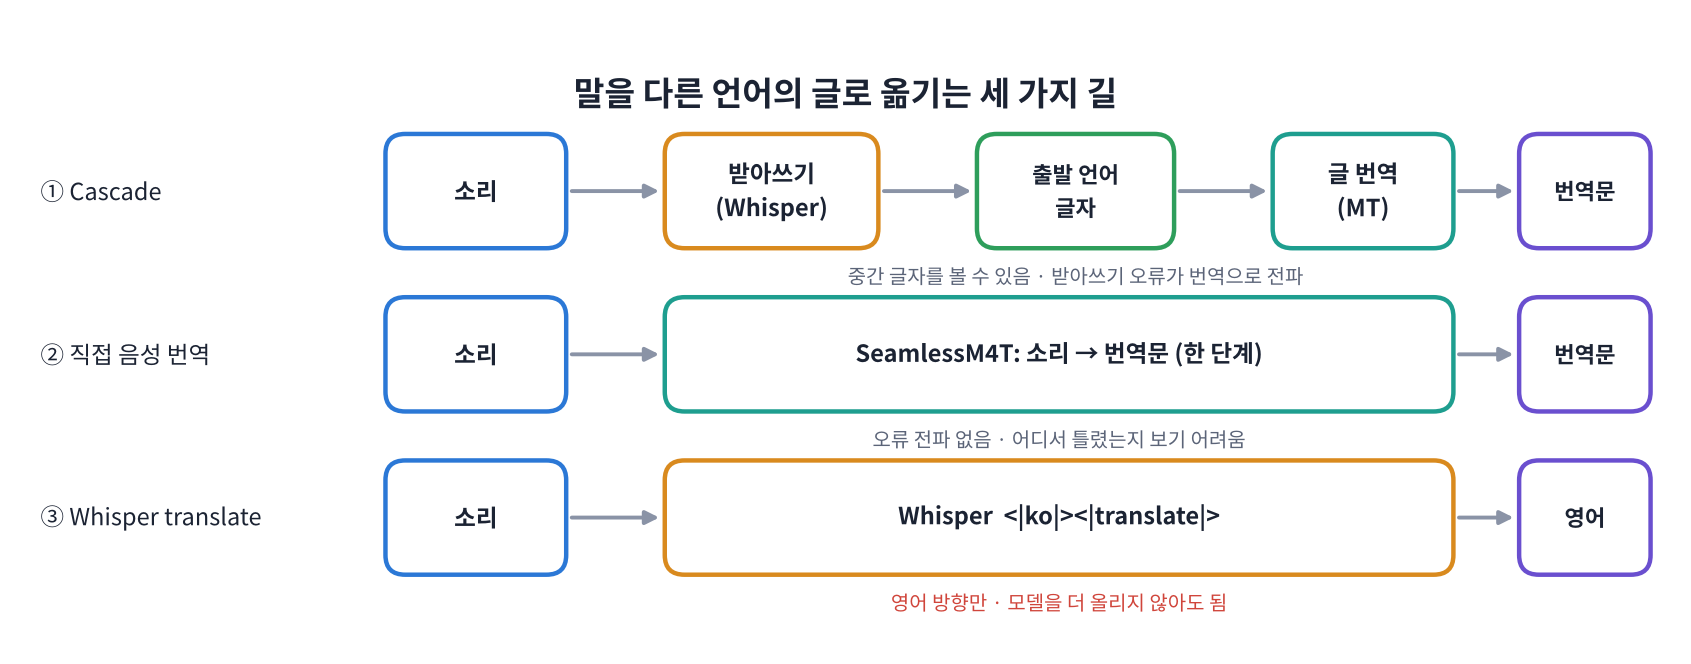

| 길 | 과정 | 장점 | 약점 |
|---|---|---|---|
| ① **Cascade** | 받아쓰기(Whisper) → 글 번역(MT) | 중간 글자를 볼 수 있어 고치고 검사하기 쉬움. 부품을 따로 바꿀 수 있음 | 받아쓰기 오류가 번역으로 **전파**됨. 두 단계의 지연 |
| ② **직접 음성 번역** | 소리 → 번역문 (SeamlessM4T) | 한 단계. 받아쓰기 오류의 전파가 없음 | 중간 글자가 없어 어디서 틀렸는지 알기 어려움 |
| ③ **Whisper translate** | 소리 → 영어 글 | 모델을 더 올리지 않아도 됨 | **영어 방향만**. 용어 · 말투를 조절하기 어려움 |

오늘의 번역 모델은 Meta의 **SeamlessM4T v2**입니다. 한 모델이 글 → 글, 소리 → 글, 소리 → 소리 번역을 모두 합니다. 그래서 ①의 글 번역과 ②의 직접 음성 번역에 **같은 모델**을 써서, 차이가 '길' 때문인지 볼 수 있습니다(어제의 "같은 머리" 원칙).

> 💬 **쉽게 말하면**: ①은 통역사가 **받아 적은 뒤** 옮기는 것이고, ②는 **들으면서 바로** 옮기는 것입니다.

> ⚠️ SeamlessM4T v2는 **비상업용 라이선스(CC BY-NC 4.0)** 입니다. 수업 · 연구에는 쓸 수 있지만 서비스에 넣으려면 다른 번역 모델(상용 API, NLLB 계열의 라이선스 확인, LLM 번역 등)을 검토해야 합니다.

> 🎬 **애니메이션 D38-3:** [번역의 세 가지 길](https://imguru-mooc.github.io/AI_Voice/day38/animation.html#paths) — 받아쓰기에서 낱말 하나가 틀렸을 때 세 길의 결과가 어떻게 달라지는지

In [ ]:
# 🌐 번역 모델 불러오기: SeamlessM4T v2 large (약 9 GB 내려받기 · T4에서 반정밀도 약 5 GB · 3 ~ 5분)
MT_NAME, LANG3 = "facebook/seamless-m4t-v2-large", {"ko": "kor", "en": "eng"}     # Seamless의 언어 이름은 세 글자
MT_OK = False
try:
    from transformers import AutoProcessor, SeamlessM4Tv2Model
    mt_proc = AutoProcessor.from_pretrained(MT_NAME)
    mt = SeamlessM4Tv2Model.from_pretrained(MT_NAME, dtype=torch.float16 if GPU else torch.float32).to(DEVICE).eval()
    MT_OK = True
    print("번역 모델:", MT_NAME, "· 글 → 글, 소리 → 글, 소리 → 소리 (비상업용 라이선스)")
except Exception as e:
    print(f"⚠️ 번역 모델을 올리지 못했습니다 ({type(e).__name__}: {str(e)[:120]})")
    print("   아래 셀은 끝까지 실행되지만 번역 자리에 안내 문구가 나옵니다. 런타임이 T4인지 확인하고 다시 실행하세요.")

In [ ]:
# ⭐ 핵심 코드: 글 → 글 번역, 소리 → 글 번역 (같은 모델)
def _generate(inputs, tgt, **kw):
    inputs = {k: (v.to(DEVICE, mt.dtype) if v.is_floating_point() else v.to(DEVICE)) for k, v in inputs.items()}
    with torch.no_grad():
        return mt.generate(**inputs, tgt_lang=LANG3[tgt], **kw)

def translate_text(text, src, tgt):                      # → (번역문, 걸린 초)
    if not MT_OK: return "(번역 모델 없음)", 0.0
    t0 = time.perf_counter()
    out = _generate(mt_proc(text=text, src_lang=LANG3[src], return_tensors="pt"), tgt, generate_speech=False)      # ⭐ 글 → 글: 출발 언어를 알려 줌
    return mt_proc.decode(out[0].tolist()[0], skip_special_tokens=True).strip(), time.perf_counter() - t0

def translate_speech(y, tgt):                            # → (번역문, 걸린 초): 받아쓰기를 거치지 않음
    if not MT_OK: return "(번역 모델 없음)", 0.0
    t0 = time.perf_counter()
    out = _generate(mt_proc(audio=to_np(y), sampling_rate=SR, return_tensors="pt"), tgt, generate_speech=False)    # ⭐ 소리 → 글: 출발 언어는 모델이 알아서
    return mt_proc.decode(out[0].tolist()[0], skip_special_tokens=True).strip(), time.perf_counter() - t0

a, sec_a = translate_text(EN[1]["text"], "en", "ko"); b, sec_b = translate_speech(EN[1]["wav"], "ko")
print("원문        :", EN[1]["text"]); print("참조 번역   :", EN[1]["ref"])
print(f"글 → 글     : {a}  ({sec_a:.2f}초)"); print(f"소리 → 글   : {b}  ({sec_b:.2f}초)")
c, _ = translate_text(KO[4]["text"], "ko", "en"); print("\n원문        :", KO[4]["text"]); print("글 → 글     :", c)
if MT_OK:                                                # 🎧 소리 → 소리: 번역한 목소리까지 한 모델이 만듦 (16 kHz)
    try:
        wav = _generate(mt_proc(audio=to_np(EN[1]["wav"]), sampling_rate=SR, return_tensors="pt"), "ko")[0]
        play(wav, SR, "소리 → 소리 (SeamlessM4T가 만든 한국어 음성)")
    except Exception as e:
        print(f"(소리 → 소리 시연은 건너뜀: {type(e).__name__})")
verify(isinstance(a, str) and isinstance(b, str) and len(a) > 0 and (not MT_OK or re.search("[가-힣]", a) and re.search("[A-Za-z]", c)),
       "영어 → 한국어 번역에는 한글이, 한국어 → 영어 번역에는 영문자가 들어 있음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
mt_proc(text=text, src_lang=LANG3[src], return_tensors="pt")
mt_proc(audio=to_np(y), sampling_rate=SR, return_tensors="pt")
mt.generate(**inputs, tgt_lang=LANG3[tgt], generate_speech=False)
```

**해설**: 두 함수의 차이는 **입력을 만드는 한 줄**뿐입니다. 글이면 `text=`와 출발 언어(`src_lang`), 소리면 `audio=`와 표본화율을 줍니다. 그 뒤의 `generate`는 같고, 도착 언어(`tgt_lang`)만 정해 줍니다. `generate_speech=False`를 빼면 번역문을 다시 **목소리로까지** 만들어 돌려줍니다(아래 🎧). 이 목소리는 모델에 들어 있는 한 가지 목소리라서, 우리 병원의 목소리(Edge TTS)로 읽으려면 글까지만 받고 TTS를 따로 붙입니다. 언어 이름은 Whisper가 두 글자(`ko` · `en`), Seamless가 세 글자(`kor` · `eng`)라서 `LANG3`으로 바꿔 줍니다. 모델마다 언어 이름이 다른 것은 다국어 서비스에서 **가장 흔한 버그의 원인**입니다. 번역문은 실행 환경에 따라 조금씩 다를 수 있고, 참조 번역과 낱말이 달라도 뜻이 맞을 수 있습니다. 그 '맞음'을 어떻게 숫자로 재는지가 다음 주제입니다.

</details>

In [ ]:
# 🧪 회화 12문장을 세 가지 길로 번역 (T4 약 1분)
def run_paths(p):
    rows = []
    t0 = time.perf_counter(); heard = stt(p["wav"], p["src"]); stt_sec = time.perf_counter() - t0
    hyp, mt_sec = translate_text(heard, p["src"], p["tgt"])
    rows.append(dict(길="① Cascade", 받아쓰기=heard, 번역=hyp, 초=stt_sec + mt_sec))
    hyp, sec = translate_speech(p["wav"], p["tgt"])
    rows.append(dict(길="② 직접 음성 번역", 받아쓰기="-", 번역=hyp, 초=sec))
    if p["tgt"] == "en":                                 # Whisper translate는 영어 방향만
        t0 = time.perf_counter(); hyp = stt(p["wav"], p["src"], "translate")
        rows.append(dict(길="③ Whisper translate", 받아쓰기="-", 번역=hyp, 초=time.perf_counter() - t0))
    return [dict(r, 방향=f'{p["src"]} → {p["tgt"]}', 원문=p["text"], 참조=p["ref"], terms=p["terms"]) for r in rows]

HYP = pd.DataFrame([r for p in PAIRS for r in run_paths(p)])
with pd.option_context("display.max_colwidth", 60):
    display(HYP[HYP.원문.isin([EN[3]["text"], KO[4]["text"]])][["길", "원문", "받아쓰기", "번역", "참조"]])
print(f"번역 {len(HYP)}개 완료 (영어 → 한국어 {len(EN)}문장 × 2가지 길 · 한국어 → 영어 {len(KO)}문장 × 3가지 길)")

### 2-1. 번역이 잘됐는지 숫자로: BLEU · chrF · 용어 정확도

번역에는 정답이 하나가 아닙니다. 그래서 **사람이 쓴 참조 번역과 얼마나 겹치는지**를 잽니다.

| 지표 | 재는 것 | 한계 |
|---|---|---|
| **BLEU** | 번역과 참조가 공유하는 **1 ~ 4개짜리 낱말 묶음(n-gram)** 의 비율 × 짧은 번역 벌점 | 뜻이 같아도 낱말이 다르면 낮음. 한국어는 띄어쓰기 단위가 길어 **글자 단위**로 잼 |
| **chrF** | **글자** n-gram의 겹침 (정밀도와 재현율) | 어미 · 조사가 다양한 한국어에 BLEU보다 안정적. 그래도 겉모습만 봄 |
| **COMET** | 원문 · 번역 · 참조를 신경망에 넣어 **뜻이 가까운지** 채점 | 사람 평가와 가장 잘 맞지만 모델이 크고(약 2 GB) 점수의 뜻이 직관적이지 않음 |
| **용어 정확도** | '사랑니 · 페니실린 · 두 시간 · 하지 마세요'처럼 **꼭 맞아야 하는 낱말**이 있는지 | 목록을 사람이 만들어야 함. 의료 통역에서는 이것이 가장 중요 |

📐 **핵심 식 하나**: `BLEU = 짧은 번역 벌점 × (1-gram · 2-gram · 3-gram · 4-gram 정밀도의 기하 평균)`

👣 **한 단계씩** (참조 `나는 학교에 갑니다`, 번역 `나는 학교에 간다`를 글자 단위로)
1. 번역의 글자 n-gram 가운데 **참조에도 있는 것**의 비율 = n-gram 정밀도 (n = 1, 2, 3, 4)
2. 네 정밀도의 기하 평균
3. 번역이 참조보다 **짧으면 벌점**: `exp(1 − 참조 길이 ÷ 번역 길이)`, 같거나 길면 1

> 💬 **쉽게 말하면**: BLEU는 "모범 답안과 같은 표현을 얼마나 썼나", 용어 정확도는 "**틀리면 안 되는 낱말**을 맞혔나"입니다.

> 🍎 **비유**: 서술형 답안을 채점할 때 모범 답안과 겹치는 구절에 밑줄을 긋는 것이 BLEU입니다. "네"라고만 쓰면 밑줄 친 비율은 100%지만 너무 짧으니 감점합니다. 그것이 짧은 번역 벌점입니다.

> 🎬 **애니메이션 D38-4:** [BLEU](https://imguru-mooc.github.io/AI_Voice/day38/animation.html#bleu) — 번역을 바꿔 가며 겹치는 n-gram과 벌점이 어떻게 달라지는지

In [ ]:
# ✍️ 직접 작성 2 (2교시): BLEU의 '짧은 번역 벌점(brevity penalty)'
# hyp_len은 번역의 길이, ref_len은 참조의 길이입니다(둘 다 1 이상).
# 번역이 참조보다 짧으면 exp(1 - ref_len / hyp_len)을, 같거나 길면 1.0을 돌려주세요. (1 ~ 3줄, math.exp를 쓰세요)
def brevity_penalty(hyp_len, ref_len):
    ...                                                  # ← 이 줄을 지우고 작성하세요

if practice(lambda: [brevity_penalty(10, 10), brevity_penalty(12, 10), brevity_penalty(5, 10), brevity_penalty(9, 10), brevity_penalty(1, 10)],
            [1.0, 1.0, 0.36788, 0.89484, 0.00012341], tol=1e-4):
    for h in [10, 9, 7, 5, 3]:
        print(f"참조 10글자 · 번역 {h:>2}글자 → 벌점 {brevity_penalty(h, 10):.3f}")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 번역이 같거나 길면 벌점이 없습니다: `if hyp_len >= ref_len: return 1.0`.
2. 짧으면 `math.exp(1 - ref_len / hyp_len)`을 돌려줍니다.
3. 한 줄로 쓰면 `return 1.0 if hyp_len >= ref_len else math.exp(1 - ref_len / hyp_len)`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def brevity_penalty(hyp_len, ref_len):
    return 1.0 if hyp_len >= ref_len else math.exp(1 - ref_len / hyp_len)
```

**해설**: n-gram 정밀도만 보면 **짧게 쓸수록 유리**합니다. "네"라고만 번역해도 그 한 글자가 참조에 있으면 정밀도는 100%입니다. 그래서 번역이 참조보다 짧을 때 점수를 깎습니다. 번역이 참조의 절반(5 ÷ 10)이면 `exp(1 − 2) = 0.368`, 90%(9 ÷ 10)이면 `exp(1 − 1.11) = 0.895`입니다. 길 때는 벌점이 없는데, 쓸데없이 긴 번역은 n-gram 정밀도가 스스로 낮아지기 때문입니다. `ref_len / hyp_len`의 위아래를 바꾸면(`hyp_len / ref_len`) 세 번째 시험에서 `exp(0.5) = 1.65`가 나와 틀립니다. 벌점은 1을 넘을 수 없습니다.

</details>

In [ ]:
# ⭐ 핵심 코드: 번역 품질 재기 — n-gram 정밀도(손으로) · BLEU · chrF(sacrebleu) · 용어 정확도
def ngrams(tokens, n):
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]

def ngram_precision(hyp, ref, n):                        # 번역의 n-gram 가운데 참조에도 있는 것의 비율 (같은 n-gram은 참조에 나온 횟수까지만 인정)
    h, r = ngrams(hyp, n), ngrams(ref, n)
    if not h: return 0.0
    left = {g: r.count(g) for g in set(r)}; hit = 0
    for g in h:
        if left.get(g, 0) > 0: hit += 1; left[g] -= 1    # ⭐ 한 번 쓴 참조 n-gram은 다시 쓰지 못함
    return hit / len(h)

def quality(hyps, refs, lang):                           # 문장 묶음 전체의 BLEU · chrF
    tok = "char" if lang == "ko" else "13a"              # ⭐ 한국어는 글자 단위, 영어는 낱말 단위
    return sacrebleu.corpus_bleu(hyps, [refs], tokenize=tok).score, sacrebleu.corpus_chrf(hyps, [refs]).score

def term_score(hyp, groups):                             # 꼭 있어야 할 낱말 묶음 가운데 번역에 들어 있는 비율
    return sum(any(w.lower() in hyp.lower() for w in g) for g in groups) / len(groups)                             # ⭐ 묶음마다 하나라도 있으면 통과

h, r = list("나는학교에간다"), list("나는학교에갑니다")
print("글자 n-gram 정밀도 (번역 '나는 학교에 간다' · 참조 '나는 학교에 갑니다'):", [round(ngram_precision(h, r, n), 2) for n in (1, 2, 3, 4)])
rows = []
for (d, path), g in HYP.groupby(["방향", "길"], sort=False):
    bleu, chrf = quality(list(g.번역), list(g.참조), d[-2:])
    rows.append({"방향": d, "길": path, "BLEU": round(bleu, 1), "chrF": round(chrf, 1), "용어 정확도": f"{np.mean([term_score(a, t) for a, t in zip(g.번역, g.terms)]):.0%}", "평균 시간(초)": round(g.초.mean(), 2)})
QUALITY = pd.DataFrame(rows); display(QUALITY)
miss = [(r.길, r.원문[:26], r.번역[:40]) for r in HYP.itertuples() if term_score(r.번역, r.terms) < 1]
print(f"용어를 놓친 번역 {len(miss)}개:"); [print("  ", m) for m in miss[:6]]
verify(abs(ngram_precision(h, r, 1) - 6 / 7) < 1e-9 and quality(["나는 학교에 갑니다"], ["나는 학교에 갑니다"], "ko")[0] > 99 and term_score("Please do NOT eat for 2 hours", [["two", "2"], ["not", "n't"]]) == 1.0,
       "1-gram 정밀도 6/7 · 참조와 똑같은 번역의 BLEU는 100 · 용어 검사는 대소문자를 가리지 않음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
if left.get(g, 0) > 0: hit += 1; left[g] -= 1
tok = "char" if lang == "ko" else "13a"
return sum(any(w.lower() in hyp.lower() for w in g) for g in groups) / len(groups)
```

**해설**: `ngram_precision`의 핵심은 **같은 n-gram을 참조에 나온 횟수까지만 인정**하는 것입니다. 이것이 없으면 "네 네 네 네"가 참조의 "네" 하나와 네 번 겹쳐 100%가 됩니다. 실제 점수는 검증된 도구 `sacrebleu`로 냅니다. 논문의 BLEU 숫자를 서로 비교할 수 있는 것은 모두 같은 도구 · 같은 토큰화로 재기 때문입니다. **한국어는 `tokenize="char"`** 로 글자 단위로 잽니다. '갑니다'와 '가요'는 띄어쓰기 단위로는 완전히 다른 낱말이지만 글자로는 일부 겹칩니다. 그래서 **한국어 방향과 영어 방향의 BLEU 숫자를 서로 비교하면 안 됩니다**(재는 단위가 다릅니다). 같은 방향 안에서 길끼리만 비교하세요. 표의 숫자가 낮게 보여도 놀라지 마세요. 참조가 하나뿐이고 문장이 6개뿐이라 숫자가 크게 흔들립니다. 그래서 **용어 정확도**와 `용어를 놓친 번역` 목록을 함께 봅니다. "두 시간 동안 드시지 마세요"에서 `not`이 빠진 번역은 BLEU가 높아도 **위험한 번역**입니다.

</details>

**❓ 생각해 보기**
1. 같은 방향에서 ① Cascade와 ② 직접 음성 번역의 차이가 큰 문장을 `HYP`에서 찾아보세요. ①이 틀렸다면 **받아쓰기**에서 틀렸나요, **번역**에서 틀렸나요? (①은 중간 글자가 있어 구분할 수 있습니다.)
2. 번역이 "치아 클리닝을 예약하고 싶어요"이고 참조가 "스케일링을 예약하고 싶어요"라면 BLEU는 낮습니다. 틀린 번역인가요? 이런 경우를 COMET은 어떻게 다르게 볼까요?
3. 병원 통역에서 BLEU 30 · 용어 정확도 100%인 시스템과 BLEU 45 · 용어 정확도 80%인 시스템 가운데 어느 쪽을 고르겠습니까?

> 💡 **COMET을 직접 재 보려면** `pip install unbabel-comet` 뒤 `Unbabel/wmt22-comet-da` 모델(약 2 GB)을 내려받아 `model.predict([{"src": 원문, "mt": 번역, "ref": 참조}, …])`를 부릅니다. Colab의 기본 패키지와 버전이 부딪칠 수 있어 오늘 노트북에는 넣지 않았습니다. 새 런타임에서 따로 해 보세요.

> ⏸️ **2교시 끝.** 🎬 D38-3 · D38-4의 **▶ 시연 보기**를 돌려 보세요.

## Part 3. 동시통역: 언제 옮기기 시작할 것인가  ·  3교시

지금까지는 문장을 **끝까지 들은 뒤** 옮겼습니다. 환자가 10초 동안 말하면 통역은 10초 뒤에야 시작됩니다. 사람 동시통역사는 문장이 끝나기 전에 옮기기 시작합니다. 기계도 그렇게 할 수 있습니다. 다만 **너무 일찍 옮기면 틀립니다.**

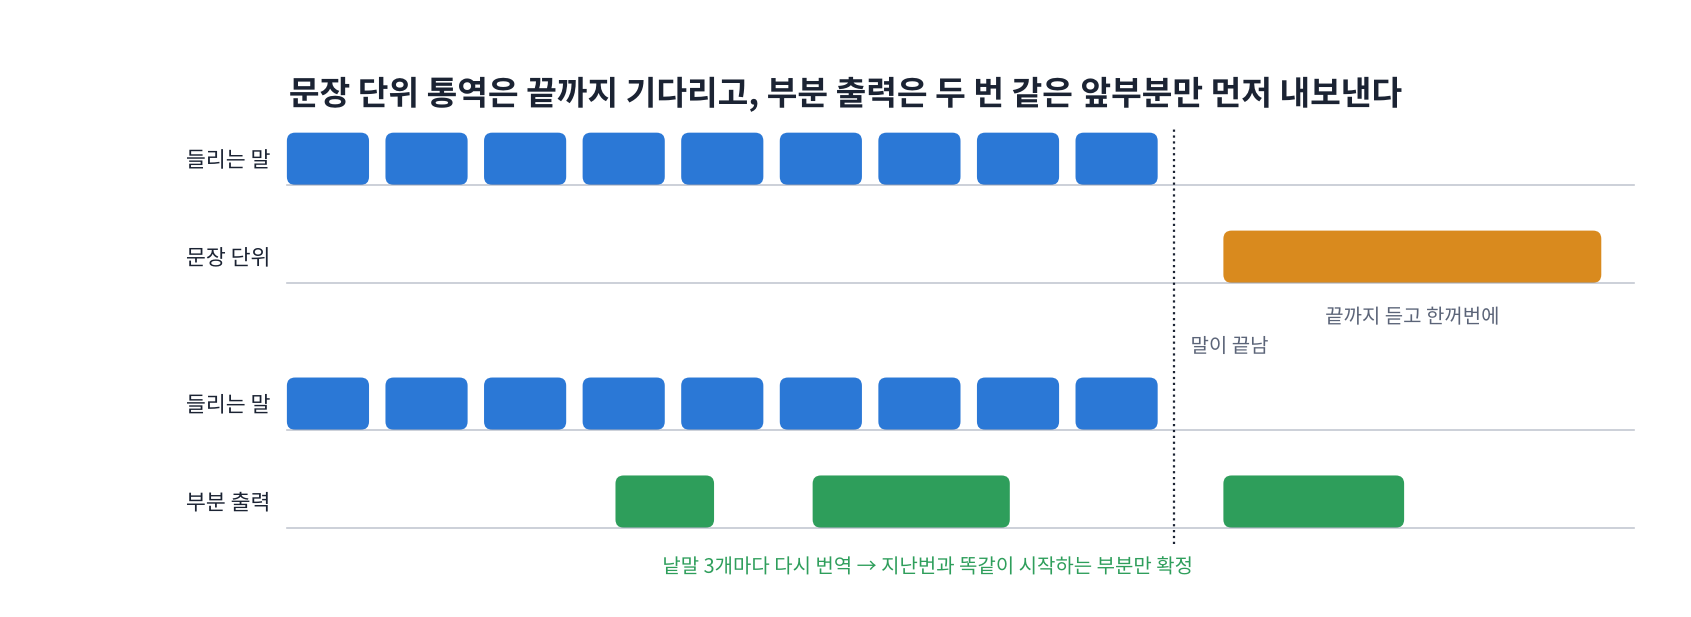

| 방식 | 옮기기 시작 | 지연 | 위험 |
|---|---|---|---|
| **문장 단위** | 문장이 끝난 뒤 | 문장 길이 + 번역 시간 | 없음 (끝까지 듣고 옮김) |
| **부분 출력** | 낱말이 몇 개 들어올 때마다 앞부분을 다시 번역 | 짧음 | 뒤의 낱말을 듣고 **앞의 번역이 뒤집힘** |

뒤집힘이 생기는 가장 큰 이유는 **어순**입니다. 한국어는 동사가 문장 끝에 옵니다. "예약을 … **바꾸고 싶습니다**"를 영어로 옮기려면 맨 앞에 "I would like to **change**"가 와야 하는데, 그 낱말은 한국어 문장의 **마지막**에 나옵니다.

👣 **부분 출력을 안전하게 만드는 규칙 (D8의 LocalAgreement와 같은 생각)**
1. 낱말이 `k`개 들어올 때마다 지금까지의 앞부분을 번역
2. **이번 번역과 지난번 번역이 똑같이 시작하는 부분**(공통 앞부분)만 '확정'해서 내보냄
3. 확정한 것은 다시 바꾸지 않음. 문장이 끝나면 나머지를 모두 내보냄

> 💬 **쉽게 말하면**: 두 번 연속 같은 말이 나온 부분만 믿습니다.

> 🍎 **비유**: 자막을 치는 사람이 화면에 글자를 띄웠다가 지우고 고쳐 쓰면 읽는 사람이 혼란스럽습니다. 그래서 확실해진 데까지만 띄웁니다. 소리(TTS)는 **이미 말한 것을 지울 수 없기** 때문에 이 규칙이 더 중요합니다.

> 🎬 **애니메이션 D38-5:** [어순과 통역](https://imguru-mooc.github.io/AI_Voice/day38/animation.html#order) · **D38-6:** [문장 단위 vs 부분 출력](https://imguru-mooc.github.io/AI_Voice/day38/animation.html#simul)

In [ ]:
# ⭐ 핵심 코드: 문장 단위 통역과 부분 출력 통역의 시간 흐름 (번역 모델을 여러 번 부름 · T4 약 30초)
def simul(text, src, tgt, dur, k=3):                     # dur: 말하는 데 걸린 시간(초) · k: 낱말 몇 개마다 다시 번역할지
    words = text.split(); n = len(words); arrive = [dur * (i + 1) / n for i in range(n)]        # 낱말이 귀에 도착하는 시각 (고르게 말한다고 가정)
    full, mt_sec = translate_text(text, src, tgt); full = full.split()
    sentence = [(arrive[-1] + mt_sec, w) for w in full]                                          # 문장 단위: 끝까지 듣고 한꺼번에
    partial, prev, done, flips = [], [], 0, 0
    for i in list(range(k, n, k)) + [n]:
        hyp, sec = translate_text(" ".join(words[:i]), src, tgt); hyp = hyp.split(); t = arrive[i - 1] + sec
        same = 0
        while same < min(len(hyp), len(prev)) and hyp[same] == prev[same]: same += 1             # ⭐ 지난번 번역과 똑같이 시작하는 낱말 수
        flips += sum(a != b for a, b in zip(prev, hyp))                                          # 지난번과 달라진 낱말 수 (확정 전이라 화면에는 안 나감)
        upto = len(hyp) if i == n else same                                                      # ⭐ 문장이 끝났으면 전부, 아니면 공통 앞부분까지만 확정
        partial += [(t, w) for w in hyp[done:upto]]; done = max(done, upto); prev = hyp
    wrong = sum(a != b for a, b in zip([w for _, w in partial], full))                           # 일찍 확정했는데 끝까지 듣고 보니 달랐던 낱말 수
    return dict(words=words, arrive=arrive, sentence=sentence, partial=partial, flips=flips, wrong=wrong, dur=dur)

LONG = {"en": "I would like to move my wisdom tooth extraction from next Wednesday at two to Friday morning at ten.",
        "ko": "다음 주 수요일 오후 두 시에 사랑니를 뽑기로 한 예약을 금요일 오전 열 시로 바꾸고 싶습니다."}
SIMUL = {}
for src in ["en", "ko"]:
    y = speak(LONG[src], voice=PATIENT if src == "en" else STAFF)
    SIMUL[src] = simul(LONG[src], src, "ko" if src == "en" else "en", len(y) / SR)             # ✏️ k=2, k=5로 바꿔 보기
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
rows = []
for ax, (src, s) in zip(axes, SIMUL.items()):
    ax.step([0] + s["arrive"], range(len(s["words"]) + 1), where="post", color="#7B8496", label="source words heard")
    for name, col in [("sentence", "#D98A1E"), ("partial", "#1E9E8F")]:
        t = [x[0] for x in s[name]]; ax.step([0] + t, range(len(t) + 1), where="post", color=col, label=f"{name}: target words out")
        rows.append({"방향": f'{src} → {"ko" if src == "en" else "en"}', "방식": "문장 단위" if name == "sentence" else "부분 출력", "첫 낱말(초)": round(t[0], 2) if t else None,
                     "평균 출력 시각(초)": round(float(np.mean(t)), 2) if t else None, "마지막 낱말(초)": round(t[-1], 2) if t else None, "말한 시간(초)": round(s["dur"], 2),
                     "확정 전 뒤집힌 낱말": s["flips"] if name == "partial" else 0, "확정 뒤 틀린 낱말": s["wrong"] if name == "partial" else 0})
    ax.axvline(s["dur"], color="k", ls=":", lw=1); ax.set_xlabel("time (s) · dotted = speaker finished"); ax.set_ylabel("words"); ax.set_title(f"{src} speech", fontsize=10); ax.legend(fontsize=7)
plt.tight_layout(); plt.show(); display(pd.DataFrame(rows))
print("부분 출력으로 확정된 순서 (ko → en):", " ".join(w for _, w in SIMUL["ko"]["partial"]))
s = SIMUL["en"]
verify(len(s["partial"]) == len(s["sentence"]) and all(a[0] <= b[0] for a, b in zip(s["partial"], s["partial"][1:])) and (not MT_OK or s["partial"][0][0] <= s["sentence"][0][0]),
       "부분 출력도 문장 단위와 같은 수의 낱말을 시간 순서대로 내보냈고, 첫 낱말은 더 일찍(또는 같은 때) 나옴")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
while same < min(len(hyp), len(prev)) and hyp[same] == prev[same]: same += 1
upto = len(hyp) if i == n else same
partial += [(t, w) for w in hyp[done:upto]]; done = max(done, upto)
```

**해설**: `same`은 이번 번역과 지난번 번역이 **맨 앞부터 똑같은 낱말 수**입니다. 그만큼만 확정해서 내보내고(`hyp[done:upto]`), 이미 내보낸 것(`done`)은 다시 건드리지 않습니다. 두 번 연속 같았던 앞부분도 문장을 끝까지 듣고 나면 달라질 수 있습니다. 그 수가 표의 **'확정 뒤 틀린 낱말'** 이고, 0이 아니면 이미 내보낸 통역에 틀린 낱말이 섞였다는 뜻입니다. 그림에서 초록 선(부분 출력)이 주황 선(문장 단위)보다 **왼쪽에서** 올라가기 시작하면 일찍 옮기기 시작한 것입니다. 두 방향을 비교해 보세요. 영어 → 한국어는 앞부분("I would like to move …")이 일찍 확정되기 쉽지만, 한국어 → 영어는 동사가 문장 끝에 있어 **거의 끝까지 확정되지 않는** 경우가 많습니다. 표의 '확정 전 뒤집힌 낱말'은 내보내기 전에 번역이 바뀐 낱말 수입니다. 두 숫자가 크면 `k`를 키우거나(더 듣고 옮김) 확정 조건을 더 엄격하게(세 번 연속 같을 때) 합니다. 여기서는 낱말이 고르게 도착한다고 가정했습니다. 실제로는 D8의 스트리밍 받아쓰기가 낱말을 내보내는 시각을 씁니다. 번역 모델을 낱말 몇 개마다 다시 부르므로 **계산 비용은 여러 배**가 됩니다.

</details>

In [ ]:
# ✍️ 직접 작성 3 (3교시): 두 번역이 맨 앞부터 똑같은 낱말 수(공통 앞부분의 길이)
# a와 b는 낱말의 리스트입니다. 맨 앞부터 차례로 비교해 처음으로 달라지기 전까지의 낱말 수를 돌려주세요. (3 ~ 4줄)
def common_prefix_len(a, b):
    ...                                                  # ← 이 줄을 지우고 작성하세요

if practice(lambda: [common_prefix_len(["I", "would", "like"], ["I", "would", "like", "to"]), common_prefix_len(["I", "want"], ["I", "would"]),
                     common_prefix_len(["The"], ["I"]), common_prefix_len([], ["I"]), common_prefix_len(["a", "b", "c"], ["a", "x", "c"])], [3, 1, 0, 0, 1]):
    prev = "I want to change".split(); now = "I want to move my appointment".split(); n = common_prefix_len(prev, now)
    print("지난번:", prev); print("이번  :", now); print(f"→ 확정: {now[:n]} · 아직 미정: {now[n:]}")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 세어 나갈 변수를 0으로 시작합니다: `n = 0`.
2. 두 리스트 모두에 `n`번째 낱말이 있고 서로 같을 때만 계속합니다: `while n < len(a) and n < len(b) and a[n] == b[n]:`.
3. 반복문 안에서 `n += 1`, 끝나면 `return n`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def common_prefix_len(a, b):
    n = 0
    while n < len(a) and n < len(b) and a[n] == b[n]:
        n += 1
    return n
```

**해설**: 위 ⭐ 셀의 `same`을 구하는 부분을 함수로 떼어 낸 것입니다. 중요한 것은 **처음 달라지는 곳에서 멈춘다**는 점입니다. 다섯 번째 시험(`a b c`와 `a x c`)에서 세 번째 낱말 `c`는 서로 같지만, 두 번째에서 이미 달라졌으므로 답은 1입니다. `sum(x == y for x, y in zip(a, b))`처럼 같은 자리의 낱말을 모두 세면 2가 나와 틀립니다. 앞부분이 달라졌는데 뒤의 낱말을 확정하면 문장이 이어지지 않기 때문입니다. D8에서 스트리밍 받아쓰기의 글자를 확정할 때 쓴 LocalAgreement와 같은 생각이고, 번역 · 자막 · 실시간 요약처럼 **"계속 바뀌는 출력에서 믿을 수 있는 데까지만 내보내는"** 모든 곳에 쓰입니다.

</details>

**❓ 생각해 보기**
1. 표에서 **한국어 → 영어**의 부분 출력은 문장 단위보다 얼마나 일찍 시작했나요? 영어 → 한국어와 비교해 차이가 나는 까닭을 어순으로 설명해 보세요.
2. 병원 통역에서 "수술 전 여덟 시간 동안 금식하셔야 합니다"를 부분 출력으로 통역하면 어떤 위험이 있을까요? **지연을 줄이는 것**과 **정확한 것** 가운데 무엇이 먼저인가요?
3. 자막(글자)은 고쳐 쓸 수 있지만 소리는 이미 나간 말을 지울 수 없습니다. 그러면 자막과 음성 통역의 확정 규칙은 어떻게 달라야 할까요?

> ⏸️ **3교시 끝.** 🎬 D38-6에서 '다시 번역하는 간격'을 바꿔 뒤집힘과 지연이 맞바뀌는 모습을 보세요.

## Part 4. 한 ↔ 영 통역 에이전트: 파이프라인과 WebSocket  ·  4교시

이제 부품을 이어 **통역기**를 만듭니다. 환자가 영어로 말하면 한국어로, 직원이 한국어로 말하면 영어로 옮겨 **목소리로** 들려줍니다.

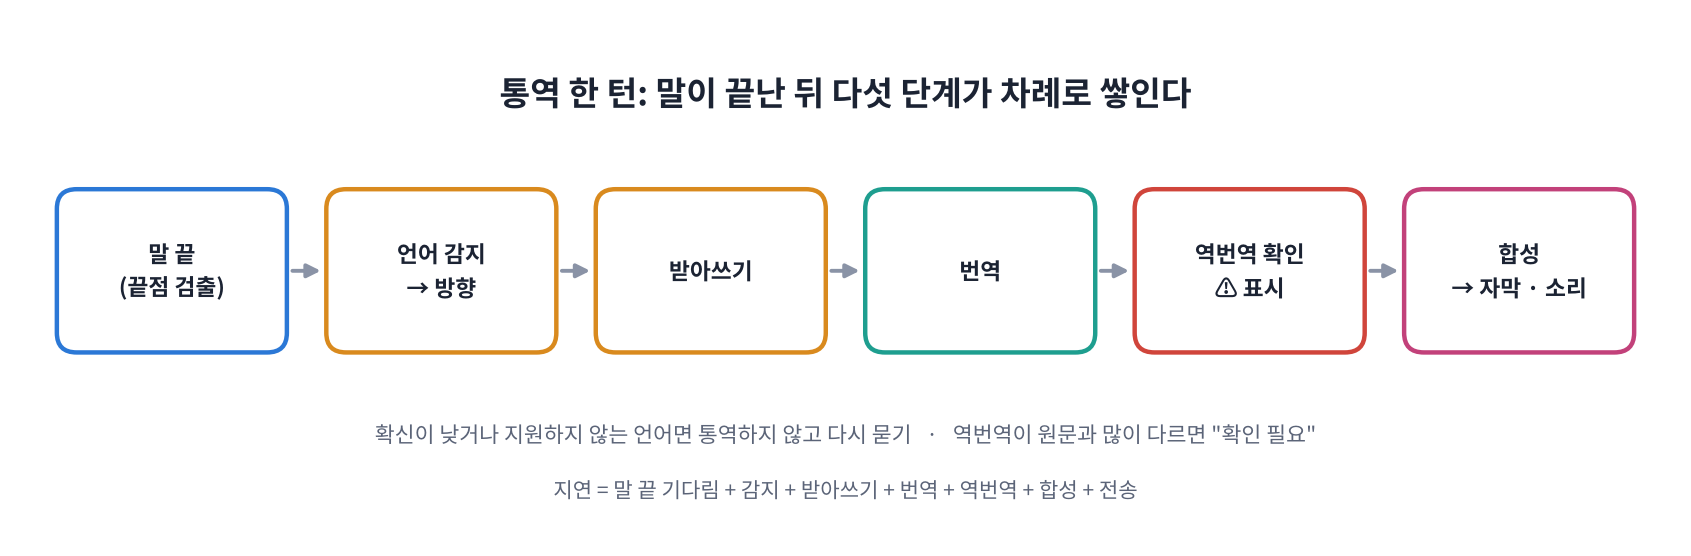

👣 **한 턴이 처리되는 순서**
1. 말이 끝남 (D31의 끝점 검출)
2. **언어 감지** → 통역 방향을 정함 (영어면 한국어로, 한국어면 영어로)
3. **받아쓰기** → **번역**
4. **역번역 확인**: 번역문을 원래 언어로 다시 옮겨 처음 글과 비교. 많이 다르면 "확인 필요" 표시
5. 도착 언어의 목소리로 **합성**해서 보냄 (자막도 함께)

### 4-1. 목소리의 일관성

통역 결과를 읽어 주는 목소리를 언어마다 다르게 쓰면 듣는 사람은 **통역기가 두 명**인 것처럼 느낍니다. 여러 언어를 한 목소리로 읽는 **다국어 음성**을 쓰면 한 사람이 두 언어를 하는 것처럼 들립니다.

| 방식 | 장점 | 약점 |
|---|---|---|
| 언어마다 다른 목소리 | 각 언어의 발음이 가장 자연스러움 | 목소리가 바뀌어 누가 말하는지 헷갈림 |
| 다국어 음성 하나 | 통역기가 한 명으로 들림 | 주 언어가 아닌 쪽의 발음 · 억양이 어색할 수 있음 |
| 화자 목소리 복제 (D19) | 환자 · 직원 본인의 목소리로 통역 | 동의 · 위조 위험. 오늘은 다루지 않음 |

In [ ]:
# 🎧 목소리의 일관성: 언어마다 다른 목소리 vs 다국어 음성 하나
ONE_VOICE = "en-US-AvaMultilingualNeural"                # ✏️ 다른 다국어 음성: ko-KR-HyunsuMultilingualNeural · en-US-AndrewMultilingualNeural
line_ko, line_en = "사랑니를 뽑아야 할 것 같습니다.", "I think we need to extract your wisdom tooth."
play(np.concatenate([speak(line_ko, "ko"), silence(0.4), speak(line_en, "en")]), SR, "언어마다 다른 목소리 (한국어 → 영어)")
try:
    if TTS_ENGINE != "edge": raise RuntimeError("예비 TTS에는 다국어 음성이 없음")
    play(np.concatenate([_edge_tts(line_ko, ONE_VOICE), silence(0.4), _edge_tts(line_en, ONE_VOICE)]), SR, f"다국어 음성 하나: {ONE_VOICE}")   # 이 목소리가 없어도 오늘의 TTS 설정은 바뀌지 않게 직접 부름
except Exception as e:
    print(f"(다국어 음성은 건너뜀: {type(e).__name__}: {str(e)[:60]})")

In [ ]:
# ✍️ 직접 작성 4 (4교시): 감지한 언어로 통역 방향과 목소리를 정하는 함수
# lang이 "ko"이면 ("en", VOICES["en"])을, "en"이면 ("ko", VOICES["ko"])를 돌려주세요.
# 그 밖의 언어(지원하지 않는 언어)면 (None, None)을 돌려줍니다. (3 ~ 5줄)
def route(lang):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W4_OK = practice(lambda: [route("ko"), route("en"), route("ja"), route("")], [("en", VOICES["en"]), ("ko", VOICES["ko"]), (None, None), (None, None)])
if W4_OK:
    for l in ["en", "ko", "ja"]:
        print(f"{LANG_KO.get(l, l)}로 말함 → 통역 방향 · 목소리: {route(l)}")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 두 언어를 서로 짝지은 사전을 만들면 편합니다: `pair = {"ko": "en", "en": "ko"}`.
2. 짝이 없는 언어면 `(None, None)`: `if lang not in pair: return None, None`.
3. 짝이 있으면 도착 언어와 그 언어의 목소리를 돌려줍니다: `tgt = pair[lang]; return tgt, VOICES[tgt]`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def route(lang):
    pair = {"ko": "en", "en": "ko"}
    if lang not in pair:
        return None, None
    tgt = pair[lang]
    return tgt, VOICES[tgt]
```

**해설**: 통역기의 '교통정리'입니다. 감지한 언어가 **출발 언어**이고 그 짝이 **도착 언어**입니다. `if lang == "ko": … elif lang == "en": … else: …`로 써도 됩니다. 사전으로 쓰면 언어가 늘어날 때(일본어 ↔ 한국어 추가) 줄 하나만 더하면 됩니다. 중요한 것은 세 번째 경우입니다. 지원하지 않는 언어가 감지됐을 때 **억지로 통역하지 않고** `(None, None)`을 돌려주면, 부르는 쪽에서 "죄송합니다. 한국어와 영어만 통역할 수 있습니다"라고 안내하거나 사람에게 넘길 수 있습니다. 1교시에 본 것처럼 언어 감지는 후보에 없는 언어도 후보 중 하나로 답하므로, 실제 서비스에서는 **감지 확신이 낮을 때**도 같은 길로 보냅니다(아래 ⭐ `interpret`의 `MIN_LANG`).

</details>

In [ ]:
# ⭐ 핵심 코드: 통역 한 턴 — 언어 감지 → 받아쓰기 → 번역 → 역번역 확인 → 합성
MIN_LANG, BACK_TH = 0.6, 40.0                            # ✏️ 언어 감지 확신의 문턱 · 역번역이 원문과 닮은 정도(chrF)의 문턱

def interpret(y):
    T = {}; t0 = time.perf_counter()
    probs = detect_lang(y); src = next(iter(probs)); T["감지"] = time.perf_counter() - t0
    if probs[src] < MIN_LANG or src not in VOICES:                                 # ⭐ 확신이 낮거나 지원하지 않는 언어면 통역하지 않음
        return dict(ok=False, src=src, conf=round(probs[src], 2), sec=T)
    tgt = "en" if src == "ko" else "ko"
    t0 = time.perf_counter(); text = stt(y, src); T["받아쓰기"] = time.perf_counter() - t0
    if not text: return dict(ok=False, src=src, conf=round(probs[src], 2), sec=T)  # 받아쓴 글이 비면 통역하지 않음
    out, T["번역"] = translate_text(text, src, tgt)
    back, T["역번역"] = translate_text(out, tgt, src)                               # ⭐ 번역문을 원래 언어로 되돌려 봄
    check = sacrebleu.sentence_chrf(back, [text]).score                             # ⭐ 되돌린 글이 처음 글과 얼마나 닮았나 (0 ~ 100)
    t0 = time.perf_counter(); audio = speak(out, tgt); T["합성"] = time.perf_counter() - t0
    return dict(ok=True, src=src, tgt=tgt, conf=round(probs[src], 2), text=text, out=out, back=back, check=round(check, 1), warn=bool(check < BACK_TH), audio=audio, sec=T)

rows = []
for p in [EN[3], KO[4], KO[2]]:
    r = interpret(p["wav"])
    rows.append({"들은 말": r.get("text", "")[:40], "통역": r.get("out", "")[:44], "역번역": r.get("back", "")[:40], "닮은 정도": r.get("check"), "확인 필요": "⚠️" if r.get("warn") else "-",
                 **{k + "(초)": round(v, 2) for k, v in r["sec"].items()}})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows))
if r["ok"]: play(r["audio"], SR, f'통역 음성 ({LANG_KO[r["tgt"]]}): {r["out"]}')
verify(r["ok"] and set(r["sec"]) == {"감지", "받아쓰기", "번역", "역번역", "합성"} and 0 <= r["check"] <= 100 and r["tgt"] != r["src"],
       "통역 한 턴에 다섯 단계의 시간이 모두 기록되고, 역번역 점수는 0 ~ 100 사이")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
if probs[src] < MIN_LANG or src not in VOICES:
back, T["역번역"] = translate_text(out, tgt, src)
check = sacrebleu.sentence_chrf(back, [text]).score
```

**해설**: 통역기가 **자기 번역을 스스로 의심하는 장치**가 두 개 들어 있습니다. 첫째, 언어 감지의 확신이 `MIN_LANG`보다 낮으면 통역하지 않습니다(`ok=False`). 엉뚱한 언어로 받아써 엉뚱한 번역을 **자신 있게** 말하는 것보다 "다시 말씀해 주세요"가 낫습니다. 둘째, **역번역 확인**입니다. 번역문을 원래 언어로 되돌려 처음 글과 글자가 얼마나 겹치는지(chrF) 봅니다. 뜻이 크게 바뀐 번역은 되돌렸을 때 처음 글과 달라지는 경우가 많습니다. 점수가 `BACK_TH`보다 낮으면 "확인 필요" 표시를 붙입니다. 이 장치는 **완전하지 않습니다.** 번역과 역번역이 똑같은 실수를 하면(예: 양쪽에서 '부정'이 사라짐) 점수가 높게 나오고, 표현만 달라져도 점수가 낮게 나옵니다. 그래서 표시가 없다고 믿는 것이 아니라, **표시가 붙은 턴을 직원 화면에 강조**해 한 번 더 확인하게 하는 용도로 씁니다. 대가는 시간입니다. 표에서 '역번역' 칸만큼 지연이 늘어납니다. 그래서 역번역은 음성을 보낸 **뒤에** 따로 돌려 자막에만 표시하는 방법도 씁니다.

</details>

### 4-2. WebSocket 통역 엔드포인트

D31에서 만든 `/ws/voice`와 같은 틀입니다. 클라이언트는 소리를 20 ms 조각으로 계속 보내고, 서버는 말이 끝날 때마다 통역해서 **자막(JSON)과 소리(바이너리)** 를 돌려보냅니다.

| 방향 | 메시지 | 내용 |
|---|---|---|
| 클라이언트 → 서버 | 바이너리 | 16 kHz PCM16 20 ms 조각 (환자든 직원이든 같은 마이크) |
| 서버 → 클라이언트 | `{"type": "caption", …}` | 감지한 언어 · 들은 말 · 통역 · 확인 필요 여부 |
| 서버 → 클라이언트 | 바이너리 | 통역 음성 (PCM16) |
| 서버 → 클라이언트 | `{"type": "audio_end"}` | 이 턴의 소리를 다 보냄 |

> 🎬 **애니메이션 D38-8:** [통역 지연](https://imguru-mooc.github.io/AI_Voice/day38/animation.html#latency) — 말 끝에서 통역 소리가 들릴 때까지의 시간이 어느 단계에서 쌓이는지

In [ ]:
# ⭐ 핵심 코드: /ws/interpret 서버 + 환자와 직원이 번갈아 말하는 클라이언트 (실제 시간으로 진행 · 약 1분)
FRAME, THRESH_DB, HANG_SEC, MIN_SPEECH = SR // 50, -38.0, 0.6, 0.25               # 20 ms 조각 · 말로 볼 크기 · 말 끝 기다림 · 너무 짧은 소리 무시

class Endpointer:                                        # D31과 같음: 20 ms 조각을 받아 말의 끝을 찾는 에너지 VAD
    def __init__(self): self.t, self.in_speech, self.quiet, self.buf = 0.0, False, 0.0, []
    def feed(self, pcm16):
        x = np.frombuffer(pcm16, dtype=np.int16).astype(np.float32) / 32768; db = 20 * np.log10(np.sqrt(np.mean(x ** 2)) + 1e-9); out = None
        if not self.in_speech and db > THRESH_DB: self.in_speech, self.quiet, self.buf = True, 0.0, []
        if self.in_speech:
            self.buf.append(x); self.quiet = self.quiet + len(x) / SR if db <= THRESH_DB else 0.0
            if self.quiet >= HANG_SEC:
                self.in_speech = False; seg = np.concatenate(self.buf)
                if len(seg) / SR - HANG_SEC >= MIN_SPEECH: out = (self.t + len(x) / SR - HANG_SEC, seg)
        self.t += len(x) / SR
        return out                                       # 말이 끝났으면 (끝난 시각, 그 구간의 소리)

app = FastAPI(title="한빛치과 통역 API")
GPU_LOCK = asyncio.Lock()                                # GPU는 한 번에 한 턴씩 (D31)

@app.websocket("/ws/interpret")
async def ws_interpret(ws: WebSocket):
    await ws.accept(); ep = Endpointer()
    try:
        while True:
            msg = await ws.receive()
            if msg["type"] == "websocket.disconnect": break
            if msg.get("bytes"):
                end = ep.feed(msg["bytes"])
                if end is None: continue
                async with GPU_LOCK:
                    r = await asyncio.to_thread(interpret, end[1])                 # ⭐ 무거운 일은 스레드로 보내 서버가 멈추지 않게
                if not r["ok"]:
                    await ws.send_json({"type": "caption", "t": round(end[0], 2), "ok": False, "src": r["src"], "conf": r["conf"]}); await ws.send_json({"type": "audio_end"}); continue
                await ws.send_json({"type": "caption", "t": round(end[0], 2), "ok": True, "src": r["src"], "tgt": r["tgt"], "text": r["text"], "out": r["out"],
                                    "warn": r["warn"], "check": r["check"], "sec": {k: round(v, 2) for k, v in r["sec"].items()}})   # ⭐ 자막 먼저
                await ws.send_bytes((np.clip(r["audio"], -1, 1) * 32767).astype(np.int16).tobytes())                               # ⭐ 이어서 통역 음성
                await ws.send_json({"type": "audio_end"})
            elif msg.get("text") == "END":
                await ws.send_json({"type": "done"}); break
    except WebSocketDisconnect:
        pass

PORT = 8038
def start_server():
    global server
    if "server" in globals() and server.started and not server.should_exit: return "이미 실행 중"
    server = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=PORT, log_level="warning"))
    threading.Thread(target=server.run, daemon=True).start()
    for _ in range(100):
        if server.started: return "시작함"
        time.sleep(0.05)
    return "시작 실패"

async def interp_call(voices, gap=0.8):                  # 클라이언트: 한 턴을 말하고, 통역 소리를 다 들은 뒤 다음 턴
    events, heard = [], []
    async with websockets.connect(f"ws://127.0.0.1:{PORT}/ws/interpret", max_size=None) as ws:
        t0 = time.perf_counter(); st = {"play_end": 0.0, "turn": asyncio.Event()}; k = 0
        async def receiver():
            async for m in ws:
                now = time.perf_counter() - t0
                if isinstance(m, bytes):
                    y = np.frombuffer(m, dtype=np.int16).astype(np.float32) / 32768; start = max(now, st["play_end"])
                    heard.append((start, y)); st["play_end"] = start + len(y) / SR; events.append({"type": "audio", "recv": round(now, 2)}); continue
                ev = json.loads(m); ev["recv"] = round(now, 2); events.append(ev)
                if ev["type"] == "audio_end": st["turn"].set()
                if ev["type"] == "done": return
        rx = asyncio.ensure_future(receiver())
        async def send(y):
            nonlocal k
            pcm = (np.clip(y, -1, 1) * 32767).astype(np.int16).tobytes()
            for i in range(0, len(pcm), FRAME * 2):
                await ws.send(pcm[i:i + FRAME * 2]); k += FRAME; await asyncio.sleep(max(0.0, t0 + k / SR - time.perf_counter()))   # 실제 시간 속도로
        spans = []
        for v in voices:
            spans.append((k / SR, v)); await send(v); st["turn"].clear(); t1 = time.perf_counter()
            while (not st["turn"].is_set() or time.perf_counter() - t0 < st["play_end"] + gap) and time.perf_counter() - t1 < 60:
                await send(silence(0.02))                # 기다리는 동안에도 조용한 소리를 계속 보냄 (마이크처럼)
        await ws.send("END"); await asyncio.wait_for(rx, 60)
    return events, heard, spans

print("서버:", start_server(), f"→ ws://127.0.0.1:{PORT}/ws/interpret")
TALK = [EN[0], KO[1], EN[3], KO[2], EN[4], KO[5]]         # 환자(영어)와 직원(한국어)이 번갈아 말함
events, heard, spans = await interp_call([p["wav"] for p in TALK])
caps = [e for e in events if e["type"] == "caption"]; rows = []
for c in caps:
    first = next((e for e in events[events.index(c):] if e["type"] == "audio"), None)
    rows.append({"말 끝(초)": c["t"], "언어": LANG_KO.get(c["src"], c["src"]), "들은 말": c.get("text", "(통역하지 않음)")[:30], "통역": c.get("out", "")[:36], "확인": "⚠️" if c.get("warn") else "-",
                 "자막 도착(초)": c["recv"], "소리 도착(초)": first["recv"] if first else None, "말 끝 → 소리(초)": round(first["recv"] - c["t"], 2) if first else None})
CALL = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", None):
    display(CALL)
n = int((max(s + len(y) / SR for s, y in heard + spans) + 0.5) * SR); mix = np.zeros(n, np.float32)
for s, y in heard + spans: i = int(s * SR); mix[i:i + len(y)] += y[:n - i]
play(mix, SR, "통역 통화 전체: 환자 · 직원의 말과 통역 음성")
verify(len(caps) == len(TALK) and events[-1]["type"] == "done" and sum(e["type"] == "audio" for e in events) == sum(c["ok"] for c in caps),
       "여섯 턴 모두 자막이 왔고, 통역한 턴마다 소리가 하나씩 도착했으며, 마지막에 done")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
r = await asyncio.to_thread(interpret, end[1])
await ws.send_json({"type": "caption", … })
await ws.send_bytes((np.clip(r["audio"], -1, 1) * 32767).astype(np.int16).tobytes())
```

**해설**: D31의 `/ws/voice`에서 '답을 만드는 부분'만 `interpret`으로 바꾼 것입니다. 받아쓰기 · 번역 · 합성은 몇 초가 걸리는 무거운 일이라 `asyncio.to_thread`로 **다른 스레드**에 보냅니다. 그러지 않으면 한 사람이 통역을 기다리는 동안 서버 전체가 멈춥니다. `GPU_LOCK`은 GPU를 한 번에 한 턴만 쓰게 합니다. **자막을 소리보다 먼저** 보내는 순서도 보세요. 직원 화면에 원문과 통역, "확인 필요" 표시가 먼저 뜨고 소리가 뒤따릅니다. 표의 '말 끝 → 소리'가 통역기의 체감 지연입니다. `말 끝 기다림(0.6초) + 감지 + 받아쓰기 + 번역 + 역번역 + 합성 + 전송`이 차례로 쌓입니다. 줄이는 방법은 지금까지 배운 것들입니다. 역번역을 소리 뒤로 미루기, 문장이 길면 문장 단위로 잘라 첫 문장부터 보내기(D31), 3교시의 부분 출력, 언어를 턴마다 감지하지 않고 **채널로 고정**하기(환자 쪽 마이크는 영어, 직원 쪽은 한국어)입니다. 이 클라이언트는 한 마이크로 두 사람이 번갈아 말한다고 가정했고, 통역 음성을 다 들은 뒤에 다음 말을 합니다. 통역 음성이 마이크로 다시 들어가면 통역기가 **자기 말을 다시 통역**하므로 실제 기기에서는 D33의 에코 제거가 필요합니다.

</details>

In [ ]:
# 📋 오늘의 산출물: 통역기 성적표
print("① 번역 품질 (2교시 · 회화 12문장)"); display(QUALITY)
print("② 통역 통화의 지연 (4교시 · 실제 시간)")
ok = CALL.dropna(subset=["말 끝 → 소리(초)"])
if len(ok):
    sec = pd.DataFrame([c["sec"] for c in caps if c.get("ok")]).mean().round(2)
    display(pd.DataFrame([{"평균 말 끝 → 소리(초)": round(ok["말 끝 → 소리(초)"].mean(), 2), "말 끝 기다림": HANG_SEC, **sec.to_dict(), "확인 필요 표시": int((ok["확인"] == "⚠️").sum())}]))
else:
    print("   통역된 턴이 없습니다 (번역 모델 · 언어 감지를 확인하세요).")
print("③ 통역기를 쓰기 전에 정할 것")
display(pd.DataFrame([
    {"항목": "통역하지 않을 때", "오늘의 설정": f"언어 감지 확신 {MIN_LANG} 미만 · 한국어 · 영어가 아닐 때", "서비스에서": "다시 묻기 → 사람 통역 연결"},
    {"항목": "확인이 필요한 번역", "오늘의 설정": f"역번역 chrF {BACK_TH:.0f} 미만이면 ⚠️", "서비스에서": "직원 화면에 강조 · 약 · 알레르기 · 금식 · 금액은 글로도 보여 주기"},
    {"항목": "꼭 맞아야 하는 용어", "오늘의 설정": "회화 12문장의 terms", "서비스에서": "병원 용어집으로 번역을 검사 · 틀리면 고쳐 읽기"},
    {"항목": "번역 모델의 라이선스", "오늘의 설정": "SeamlessM4T v2 (비상업용)", "서비스에서": "상용 가능한 모델 · API로 교체"},
    {"항목": "통역 사실 알리기", "오늘의 설정": "-", "서비스에서": "\"AI 통역을 사용합니다\" 고지 · 기록 보관 규칙 (D43)"}]))

### 4-3. 한계: 의료 통역에서 기계가 틀리면

| 위험 | 예 | 대비 |
|---|---|---|
| **부정 · 숫자가 바뀜** | "드시지 **마세요**" → "eat", "두 시간" → "two days" | 용어 검사, 역번역 확인, 숫자는 화면에 글로 |
| **용어를 일반 낱말로** | 신경 치료 → "nerve treatment" (root canal이 맞음) | 병원 용어집 |
| **이름 · 약 이름** | 페니실린, 환자 이름의 철자 | 받아쓴 글자를 화면에 보여 주고 본인이 확인 (D34의 확인 절차) |
| **언어를 잘못 감지** | 짧은 "Okay"를 다른 언어로 | 확신 문턱, 직전 턴의 언어, 채널로 고정 |
| **지어낸 번역** | 조용한 구간 · 잡음을 문장으로 번역 | 끝점 검출, 너무 짧은 소리 무시 (D7의 환각 대응) |
| **말투 · 예의** | 존댓말이 반말로, 정중한 요청이 명령으로 | 번역 뒤 말투 다듬기, 표본을 사람이 확인 |

> ⚖️ **기계 통역은 보조 수단입니다.** 진단 설명 · 수술 동의 · 약 처방처럼 틀리면 안 되는 대화에는 **자격 있는 의료 통역사**가 필요합니다. 통역기는 접수 · 예약 · 길 안내 같은 낮은 위험의 대화를 맡고, 위험한 주제가 나오면 사람에게 넘기는 규칙(D36의 에스컬레이션)을 둡니다.

**❓ 생각해 보기**: 오늘 통역기에 **"이 대화는 사람 통역사에게 넘긴다"** 는 규칙을 하나 넣는다면 어떤 조건으로 하겠습니까? (예: ⚠️가 두 턴 연속, '수술 · 마취 · 알레르기' 같은 낱말이 나옴, 환자가 같은 말을 세 번 반복)

> 📝 **워크시트 25문항**(하루 한 장)을 풀고, **오답 정리**를 복사해 노션에 붙여 넣으세요. 노션에는 **글과 표만** 올립니다.

## Part 5. 정리

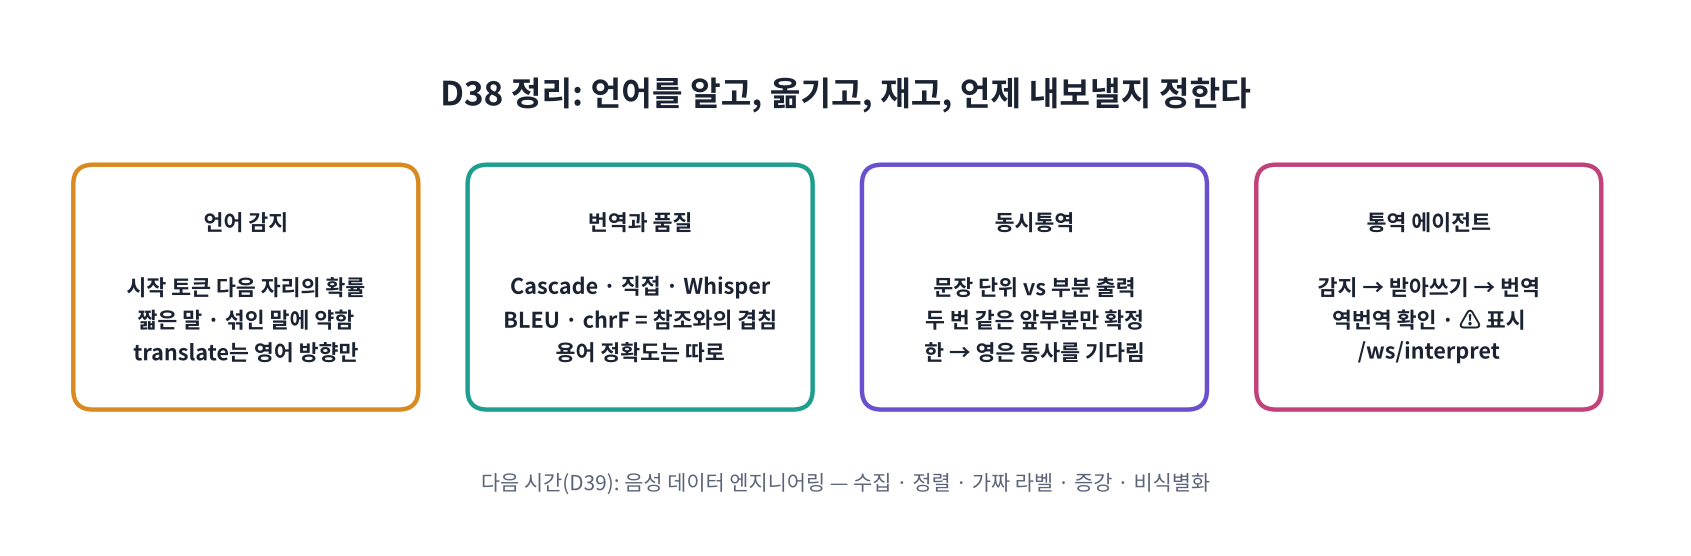

| 오늘 만든 것 | 핵심 | 한계 |
|---|---|---|
| `detect_lang` · `stt(lang, task)` | 시작 토큰 다음 자리의 확률 = 언어 감지. translate는 영어 방향만 | 짧은 말 · 섞인 문장 · 후보에 없는 언어 |
| `hangul_ratio` | 받아쓴 글의 글자 종류로 섞인 문장 찾기 | 한글로 적은 외래어는 구분 못 함 |
| `translate_text` · `translate_speech` | 같은 모델로 글 → 글, 소리 → 글 | 비상업용 라이선스 |
| `brevity_penalty` · `quality` · `term_score` | BLEU · chrF는 참조와의 겹침, 용어 정확도는 틀리면 안 되는 낱말 | 참조 하나 · 문장 6개 → 숫자가 흔들림 |
| `simul` · `common_prefix_len` | 두 번 연속 같은 앞부분만 확정 | 한국어 → 영어는 동사를 기다려야 함 |
| `route` · `interpret` · `/ws/interpret` | 감지 → 받아쓰기 → 번역 → 역번역 확인 → 합성 | 역번역이 놓치는 오역 · 단계마다 쌓이는 지연 |

**오늘의 세 문장**
1. **통역의 첫 단계는 언어를 아는 것이다. 짧은 말과 섞인 말에서는 틀린다.**
2. **번역 점수는 참조와의 겹침일 뿐이다. 틀리면 안 되는 낱말은 따로 검사한다.**
3. **일찍 옮기면 빠르고, 끝까지 들으면 정확하다. 두 번 같은 데까지만 확정한다.**

**다음 시간(D39)**: 음성 데이터 엔지니어링. 오늘 만든 통역기를 우리 병원 용어에 맞게 고치려면 **데이터**가 필요합니다. 녹음을 모으고(동의), 자르고, 글자와 맞추고, 가짜 라벨을 거르고, 이름과 번호를 지우는 과정을 만듭니다.